# Plotting results

## Librairies

In [7]:
import io
import os
import re
import sys

In [8]:
import pickle
import time
from timeit import default_timer as timer

import numpy as np
import random

In [9]:
import matplotlib.pyplot as plt
plt.style.use('ggplot')

## Plots

In [10]:
# Baseline results
baselines_d = {'trec-6':  {'last' : 92.20, 'mean' : 89.20}, 
            #    'trec-50': {'last' : 77.00, 'mean' : 76.60}, 
            #    'sst-2':   {'last' : 80.67, 'mean' : 85.72}, 
            #    'imdb':    {'last' : 81.28, 'mean' : 88.61}, 
            #    'ag-news': {'last' : 87.46, 'mean' : 90.59}
              }

In [11]:
# plot function by pooling strategy
def plot_by_ps(dataset, pooling_strategy, results_d):

    dims = list(results_d.keys())
    dims.sort()

    acc_bs = baselines_d[dataset][pooling_strategy]

    acc_esn = np.array([results_d[x]['recurrent_layer'][0] for x in dims])
    std_esn = np.array([results_d[x]['recurrent_layer'][1] for x in dims])

    acc_ll = np.array([results_d[x]['linear_layer'][0] for x in dims])
    std_ll = np.array([results_d[x]['linear_layer'][1] for x in dims])


    fig = plt.figure(figsize=(8, 4.5))

    ax = fig.add_subplot(111)

    # Baselines
    ax.axhline(y=acc_bs, linestyle='--', linewidth=3, color='grey', label=f'baseline ({pooling_strategy})', alpha=1)

    # ESNs
    ax.errorbar(dims, acc_esn, std_esn, color='C0', elinewidth=1, linewidth=2, label=f'ESN ({pooling_strategy})', marker='o', alpha=1)
    ax.fill_between(dims, acc_esn-std_esn, acc_esn+std_esn, alpha=0.2)
    # ax.plot(dims, acc_esn, color='C0', linewidth=3, label=f'ESN ({pooling_strategy})', marker='o', alpha=1)

    # Linear Layer
    ax.errorbar(dims, acc_ll, std_ll, color='C1', elinewidth=1, linewidth=2, label=f'LL ({pooling_strategy})', marker='o', alpha=1)
    ax.fill_between(dims, acc_ll-std_ll, acc_ll+std_ll, alpha=0.2)
    # ax.plot(dims, acc_ll, color='C1', linewidth=3, label=f'LL ({pooling_strategy})', marker='o', alpha=1)

    ax.set_title(dataset.upper() + f' ({pooling_strategy})', fontsize=15)
    ax.set_ylabel('test accuracy', fontsize=15)
    ax.set_xlabel('hidden dimension', fontsize=15)
    ax.tick_params(axis="x", labelsize=12)
    ax.tick_params(axis="y", labelsize=12)

    # change legend order
    handles,labels = ax.get_legend_handles_labels()
    handles = [handles[0], handles[2], handles[1]]
    labels = [labels[0], labels[2], labels[1]]

    plt.legend(handles, labels, loc='lower center', prop={'size': 12}, ncol=3, bbox_to_anchor=(0.5, -0.35))
    plt.savefig('plots/' + dataset + '-' + pooling_strategy + '.pdf', bbox_inches = 'tight')

RESULTS FILE: trec-6_results_esn_uniform_last-pooling_FINAL.pkl
RESULTS FILE: trec-6_results_esn_uniform_mean-pooling_FINAL.pkl


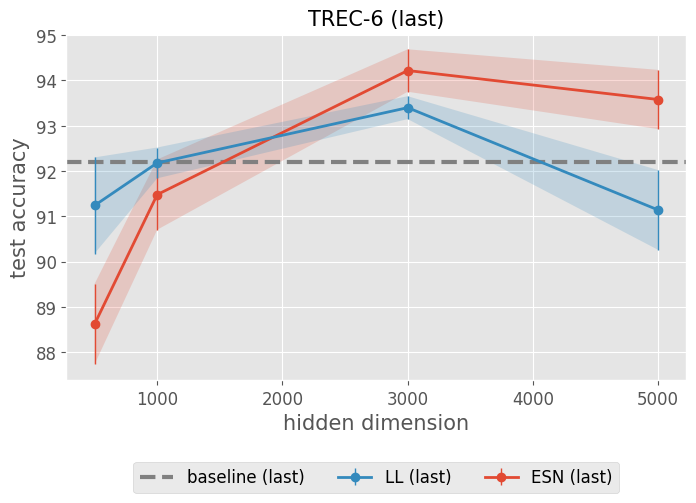

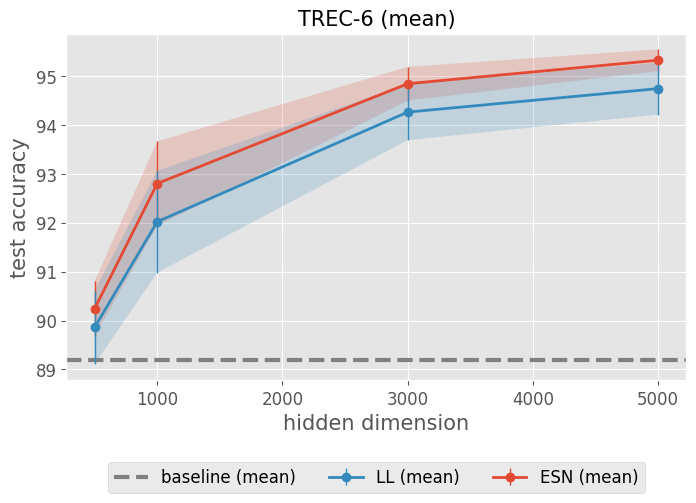

In [12]:
# create plots
RESULTS_PATH = 'C:\\Users\\AJYH\\Desktop\\UNIVERSIDAD\\GII - TI - US\\5o CURSO (2024-2025)\\TFG\esn_torch_virt_env\\esntorch\\notebooks_paper_2022\\ESN_v2\\Results\\ESN_v2' # put your path here

for dataset in ['trec-6']: #, 'trec-50', 'sst-2', 'ag-news', 'imdb']:

    for pooling_strategy in ['last', 'mean']:
            
        RESULTS_FILE = f'{dataset}_results_esn_uniform_{pooling_strategy}-pooling_FINAL.pkl'
        # RESULTS_FILE = f'{dataset}_results_{pooling_strategy}.pkl'
        print('RESULTS FILE:', RESULTS_FILE)
        
        with open(os.path.join(RESULTS_PATH, RESULTS_FILE), 'rb') as fh:
            results_d = pickle.load(fh)
            
        plot_by_ps(dataset, pooling_strategy, results_d)

In [13]:
RESULTS_PATH
trec_mean_file = 'trec-6_results_esn_uniform_mean-pooling_FINAL.pkl'
trec_last_file = 'trec-6_results_esn_uniform_last-pooling_FINAL.pkl'

In [14]:
with open(os.path.join(RESULTS_PATH, trec_mean_file), 'rb') as fh:
    results_d_mean = pickle.load(fh)

In [15]:
results_d_mean

{500: {'recurrent_layer': [90.24,
   0.5642694391866344,
   2.0681173499999206,
   0.9139601162803955],
  'linear_layer': [89.86000000000001,
   0.7539230729988303,
   1.8628326799998831,
   0.27088287783252135]},
 1000: {'recurrent_layer': [92.79999999999998,
   0.8625543461139138,
   3.9538293099996737,
   0.24668306245937277],
  'linear_layer': [92.02000000000001,
   1.0409610943738499,
   2.5458095899997715,
   0.658487781028644]},
 3000: {'recurrent_layer': [94.84,
   0.3440930106817055,
   24.017182270000195,
   1.664615894684242],
  'linear_layer': [94.26,
   0.5730619512757733,
   13.777446820000296,
   1.0725015040551793]},
 5000: {'recurrent_layer': [95.32000000000001,
   0.22271057451319867,
   71.17317122999975,
   1.7582049766550363],
  'linear_layer': [94.74,
   0.5295280917949485,
   42.70794347999981,
   0.8047044601839154]}}

In [16]:
with open(os.path.join(RESULTS_PATH, trec_last_file), 'rb') as fh:
    results_d_last = pickle.load(fh)

In [17]:
results_d_last

{500: {'recurrent_layer': [88.62,
   0.887468309293352,
   2.0059642199992593,
   1.3885648171746319],
  'linear_layer': [91.24,
   1.0613199329137266,
   1.8183521400000244,
   0.33996876142640764]},
 1000: {'recurrent_layer': [91.47999999999999,
   0.7756287771866127,
   4.276933090000239,
   0.5924539832718897],
  'linear_layer': [92.18,
   0.3400000000000005,
   2.9377550600000175,
   0.6880279899351329]},
 3000: {'recurrent_layer': [94.22,
   0.46861498055439954,
   25.713266589999513,
   2.755864031089408],
  'linear_layer': [93.4,
   0.25298221281346833,
   15.45249700000004,
   2.1207188456669415]},
 5000: {'recurrent_layer': [93.57999999999998,
   0.6539113089708734,
   97.06452717999983,
   16.83232739808819],
  'linear_layer': [91.14,
   0.8811356308764274,
   59.3243302400002,
   14.854069245139097]}}

In [18]:
# Nueva función: compara el mismo modelo con distintas estrategias de pooling
def plot_by_model(dataset, model_name, results_last, results_mean):
    dims = list(results_last.keys())
    dims.sort()

    model_display = 'ESN' if model_name == 'recurrent_layer' else 'LL'

    acc_bs_last = baselines_d[dataset]['last']
    acc_bs_mean = baselines_d[dataset]['mean']

    acc_model_last = np.array([results_last[x][model_name][0] for x in dims])
    std_model_last = np.array([results_last[x][model_name][1] for x in dims])

    acc_model_mean = np.array([results_mean[x][model_name][0] for x in dims])
    std_model_mean = np.array([results_mean[x][model_name][1] for x in dims])

    fig = plt.figure(figsize=(8, 4.5))
    ax = fig.add_subplot(111)

    # Baselines (línea discontinua para 'last', punteada para 'mean')
    ax.axhline(y=acc_bs_last, linestyle='--', linewidth=3, color='grey', label='baseline (last)', alpha=1)
    ax.axhline(y=acc_bs_mean, linestyle=':',  linewidth=3, color='grey', label='baseline (mean)', alpha=1)

    # Modelo con pooling 'last'
    ax.errorbar(dims, acc_model_last, std_model_last, color='C0', elinewidth=1, linewidth=2,
                label=f'{model_display} (last)', marker='o', alpha=1)
    ax.fill_between(dims, acc_model_last - std_model_last, acc_model_last + std_model_last, alpha=0.2)

    # Modelo con pooling 'mean'
    ax.errorbar(dims, acc_model_mean, std_model_mean, color='C1', elinewidth=1, linewidth=2,
                label=f'{model_display} (mean)', marker='o', alpha=1)
    ax.fill_between(dims, acc_model_mean - std_model_mean, acc_model_mean + std_model_mean,
                    color='C1', alpha=0.2)

    ax.set_title(f'{dataset.upper()} ({model_display})', fontsize=15)
    ax.set_ylabel('test accuracy', fontsize=15)
    ax.set_xlabel('hidden dimension', fontsize=15)
    ax.tick_params(axis="x", labelsize=12)
    ax.tick_params(axis="y", labelsize=12)

    # Reordenar leyenda: [baseline_last, model_last, baseline_mean, model_mean]
    handles, labels = ax.get_legend_handles_labels()
    handles = [handles[0], handles[2], handles[1], handles[3]]
    labels  = [labels[0],  labels[2],  labels[1],  labels[3]]

    plt.legend(handles, labels, loc='lower center', prop={'size': 12}, ncol=2, bbox_to_anchor=(0.5, -0.45))
    plt.savefig(f'plots/{dataset}-{model_display.lower()}.pdf', bbox_inches='tight')

RESULTS FILE: trec-6_results_esn_uniform_last-pooling_FINAL.pkl
RESULTS FILE: trec-6_results_esn_uniform_mean-pooling_FINAL.pkl


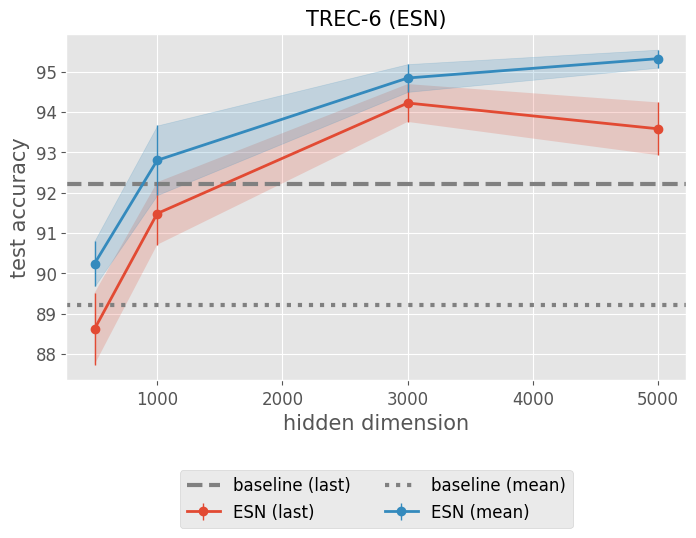

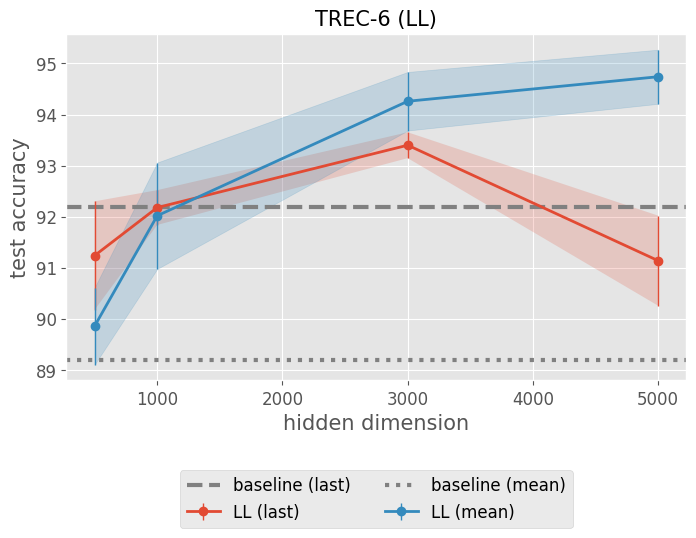

In [19]:
# Generar las gráficas por modelo (requiere RESULTS_PATH definido en la celda anterior)
for dataset in ['trec-6']:  # , 'trec-50', 'sst-2', 'ag-news', 'imdb'

    results_by_pooling = {}
    for pooling_strategy in ['last', 'mean']:
        RESULTS_FILE = f'{dataset}_results_esn_uniform_{pooling_strategy}-pooling_FINAL.pkl'
        print('RESULTS FILE:', RESULTS_FILE)
        with open(os.path.join(RESULTS_PATH, RESULTS_FILE), 'rb') as fh:
            results_by_pooling[pooling_strategy] = pickle.load(fh)

    for model_name in ['recurrent_layer', 'linear_layer']:
        plot_by_model(dataset, model_name, results_by_pooling['last'], results_by_pooling['mean'])

In [20]:
RESULTS_PATH
trec_mean_file = 'trec-6_results_esn_uniform_mean-pooling_FINAL.pkl'
trec_last_file = 'trec-6_results_esn_uniform_last-pooling_FINAL.pkl'

In [21]:
with open(os.path.join(RESULTS_PATH, trec_mean_file), 'rb') as fh:
    results_d_mean = pickle.load(fh)

In [22]:
results_d_mean

{500: {'recurrent_layer': [90.24,
   0.5642694391866344,
   2.0681173499999206,
   0.9139601162803955],
  'linear_layer': [89.86000000000001,
   0.7539230729988303,
   1.8628326799998831,
   0.27088287783252135]},
 1000: {'recurrent_layer': [92.79999999999998,
   0.8625543461139138,
   3.9538293099996737,
   0.24668306245937277],
  'linear_layer': [92.02000000000001,
   1.0409610943738499,
   2.5458095899997715,
   0.658487781028644]},
 3000: {'recurrent_layer': [94.84,
   0.3440930106817055,
   24.017182270000195,
   1.664615894684242],
  'linear_layer': [94.26,
   0.5730619512757733,
   13.777446820000296,
   1.0725015040551793]},
 5000: {'recurrent_layer': [95.32000000000001,
   0.22271057451319867,
   71.17317122999975,
   1.7582049766550363],
  'linear_layer': [94.74,
   0.5295280917949485,
   42.70794347999981,
   0.8047044601839154]}}

In [23]:
with open(os.path.join(RESULTS_PATH, trec_last_file), 'rb') as fh:
    results_d_last = pickle.load(fh)

In [24]:
results_d_last

{500: {'recurrent_layer': [88.62,
   0.887468309293352,
   2.0059642199992593,
   1.3885648171746319],
  'linear_layer': [91.24,
   1.0613199329137266,
   1.8183521400000244,
   0.33996876142640764]},
 1000: {'recurrent_layer': [91.47999999999999,
   0.7756287771866127,
   4.276933090000239,
   0.5924539832718897],
  'linear_layer': [92.18,
   0.3400000000000005,
   2.9377550600000175,
   0.6880279899351329]},
 3000: {'recurrent_layer': [94.22,
   0.46861498055439954,
   25.713266589999513,
   2.755864031089408],
  'linear_layer': [93.4,
   0.25298221281346833,
   15.45249700000004,
   2.1207188456669415]},
 5000: {'recurrent_layer': [93.57999999999998,
   0.6539113089708734,
   97.06452717999983,
   16.83232739808819],
  'linear_layer': [91.14,
   0.8811356308764274,
   59.3243302400002,
   14.854069245139097]}}